# Flow Matching in Audio Enhancement - Tutorial

Authors: Maja Byrecka, Sonia Weiss

## Overview

In this tutorial, we explore Flow Matching as a method for audio enhancement, focusing on noise reduction.

First we introduce audio representations and the core idea behind Flow Matching, then run a pretrained speech enhancement model and implement a small conditional Flow Matching model from scratch using PyTorch.

### Imports and variables definitions

In [3]:
from pathlib import Path
import json
import os
import shutil
import subprocess
import sys
import time

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import yaml

from IPython.display import Audio, Markdown, display

In [4]:
# Input audio files
DATA_DIR = Path("data")
CLEAN_PATH = DATA_DIR / "lj_clean.wav"
NOISY_PATH = DATA_DIR / "lj_noisy.wav"

# Audio representation parameters
SAMPLE_RATE = 22_050
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 80

# External model configuration
FLOWSE_REPO = Path("FlowSE").resolve()
MODEL_DIR = Path("models").resolve()

CHECKPOINT_REPO_ID = "flowse/wenetspeech4tts_Premium.pt.tar"
CHECKPOINT_FILENAME = "wenetspeech4tts_Premium.pt.tar"

VOCODER_REPO_ID = "charactr/vocos-mel-24khz"
VOCODER_FILENAMES = ("config.yaml", "pytorch_model.bin")

# Inference configuration
EXAMPLE_ID = "lj_noisy"
TRANSCRIPT = (
    "Printing, in the only sense with which we are at present "
    "concerned, differs from most if not from all the arts "
    "and crafts represented in the Exhibition"
)

# CPU resource limits
CPU_THREADS = 2

## Audio Representations

A WAV file stores audio as discrete samples. Time-frequency representations are commonly used for audio processing. Most typical formats are:
- Spectrograms - representing the magnitude of Short-time Fourier Transform (STFT) components over time;
- Mel-spectrograms - calculated as spectrograms transformed onto the mel scale, providing a compact representation corresponding to human sound perception.

In this tutorial, we will use mel-spectrograms as the input and output representations.

In [ ]:
wav_clean, sample_rate = librosa.load(CLEAN_PATH)
wav_noisy, _ = librosa.load(NOISY_PATH)

In [9]:
display(Markdown("Clean Speech: "))
display(Audio(wav_clean, rate=SAMPLE_RATE))

display(Markdown("Noisy Speech: "))
display(Audio(wav_noisy, rate=SAMPLE_RATE))

Clean Speech: 

Noisy Speech: 

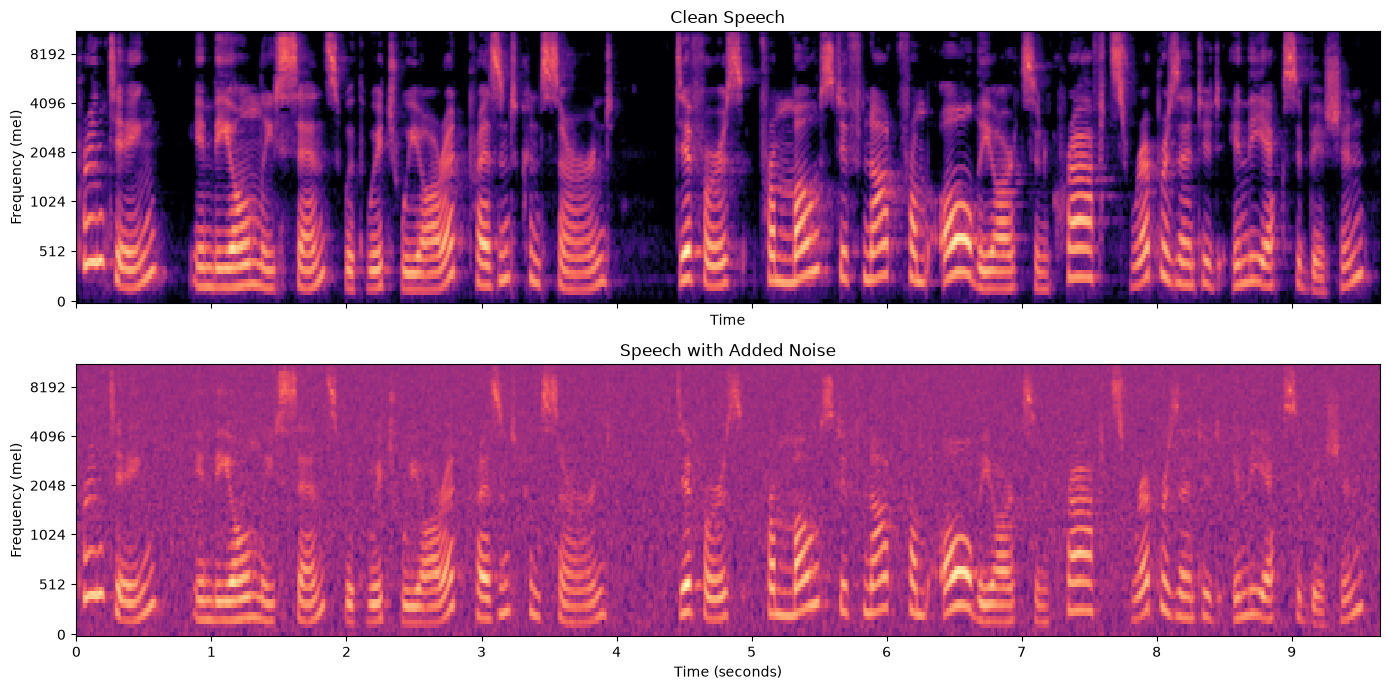

Sample rate: 22,050 Hz
Clean duration: 9.65501133786848 s
Noisy duration: 9.65501133786848 s


In [10]:
mel_clean = librosa.feature.melspectrogram(y=wav_clean, sr=sample_rate, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=0, fmax=sample_rate/2, power=2.0)
mel_noisy = librosa.feature.melspectrogram(y=wav_noisy, sr=sample_rate, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=0, fmax=sample_rate/2, power=2.0)

reference = max(float(mel_clean.max()), float(mel_noisy.max()))

mel_clean_db = librosa.power_to_db(mel_clean, ref=reference, top_db=80)
mel_noisy_db = librosa.power_to_db(mel_noisy, ref=reference, top_db=80)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

for ax, spectrogram, title in [
    (axes[0], mel_clean_db, "Clean Speech"),
    (axes[1], mel_noisy_db, "Speech with Added Noise"),
]:
    librosa.display.specshow(spectrogram, sr=SAMPLE_RATE, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", vmin=-80, vmax=0, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Frequency (mel)")

axes[-1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

print(f"Sample rate: {SAMPLE_RATE:,} Hz")
print(f"Clean duration: {len(wav_clean) / SAMPLE_RATE} s")
print(f"Noisy duration: {len(wav_noisy) / SAMPLE_RATE} s")

## Flow Matching Models

### Architecture high-level description


### FlowSE

One of the state-of-the-art flow matching architectures designed for audio enhancement task is FlowSE. 

FlowSE is a Flow Matching-based generative model designed for speech enhancement. It learns a time-dependent vector field that transforms noisy speech representations into clean speech representations by solving an ordinary differential equation (ODE). Unlike traditional denoising approaches, it models a continuous transformation from noisy to clean speech through iterative refinement.

Let's run the inference and analyze the results.

In [ ]:
def run_flowse_inference(
    noisy_audio: np.ndarray,
    sample_rate: int,
    *,
    repo_dir: Path = FLOWSE_REPO,
    model_dir: Path = MODEL_DIR,
    cpu_threads: int = CPU_THREADS,
) -> dict:
    """
    Prepare and run pretrained FlowSE speech enhancement
    """
    from huggingface_hub import hf_hub_download

    repo_dir = repo_dir.resolve()
    model_dir = model_dir.resolve()

    if not repo_dir.exists():
        subprocess.run(["git", "clone", "https://github.com/Honee-W/FlowSE.git", str(repo_dir)], check=True)

    infer_script = repo_dir / "infer.py"
    base_config_path = repo_dir / "config" / "train.yaml"
    model_dir.mkdir(parents=True, exist_ok=True)

    # Download checkpoints
    print("Downloading models...")
    checkpoint_path = Path(hf_hub_download(repo_id=CHECKPOINT_REPO_ID, filename=CHECKPOINT_FILENAME, local_dir=str(model_dir))).resolve()

    vocoder_dir = (repo_dir / "vocos-mel-24khz").resolve()
    vocoder_dir.mkdir(parents=True, exist_ok=True)

    for filename in VOCODER_FILENAMES:
        hf_hub_download(repo_id=VOCODER_REPO_ID, filename=filename, local_dir=str(vocoder_dir))

    example_dir = repo_dir / "datalist" / "tutorial" / "noisy"
    manifest_path = repo_dir / "datalist" / "tutorial" / "text.json"

    example_dir.mkdir(parents=True, exist_ok=True)
    manifest_path.parent.mkdir(parents=True, exist_ok=True)

    tutorial_input_path = example_dir / f"{EXAMPLE_ID}.wav"

    sf.write(tutorial_input_path, noisy_audio, sample_rate, subtype="PCM_16")
    manifest_path.write_text(json.dumps({EXAMPLE_ID: TRANSCRIPT}, indent=2), encoding="utf-8")

    # Preserve the test input location expected by the FlowSE setup
    test_input_path = repo_dir / "datalist" / "test" / "noisy" / f"{EXAMPLE_ID}.wav"
    test_input_path.parent.mkdir(parents=True, exist_ok=True)

    sf.write(test_input_path, noisy_audio, sample_rate, subtype="PCM_16")

    # Add CPU inference configuration
    config = yaml.safe_load(base_config_path.read_text(encoding="utf-8"))
    infer = config["infer"]

    infer["test"]["use_cuda"] = False
    infer["test"]["checkpoint"] = str(checkpoint_path.parent)
    infer["test"]["pt_name"] = checkpoint_path.name
    infer["datareader"]["mix_json"] = str(manifest_path.resolve())

    output_dir = (repo_dir / "test_out").resolve()
    output_dir.mkdir(parents=True, exist_ok=True)

    infer["save"]["dir"] = str(output_dir)

    vocoder_config = infer["nnet_conf"]["vocoder"]
    vocoder_config["is_local"] = True
    vocoder_config["local_path"] = str(vocoder_dir)

    cpu_config_path = (repo_dir / "config" / "tutorial_cpu.yaml").resolve()
    cpu_config_path.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding="utf-8")

    enhanced_path = output_dir / f"{EXAMPLE_ID}.wav"

    # Run inference with bounded CPU thread usage
    env = os.environ.copy()
    # env["CUDA_VISIBLE_DEVICES"] = ""
    env["OMP_NUM_THREADS"] = str(cpu_threads)
    env["MKL_NUM_THREADS"] = str(cpu_threads)
    env["OPENBLAS_NUM_THREADS"] = str(cpu_threads)

    print("Inference...")
    result = subprocess.run(
        [sys.executable, str(infer_script), "-conf", str(cpu_config_path)],
        cwd=repo_dir,
        env=env,
        capture_output=True,
        text=True,
        check=False,
    )

    return {
        "enhanced_path": enhanced_path,
        "checkpoint_path": checkpoint_path,
        "output_dir": output_dir,
    }

In [15]:
flowse_result = run_flowse_inference(noisy_audio=wav_noisy, sample_rate=SAMPLE_RATE)
enhanced_path = flowse_result["enhanced_path"]

print(f"Enhanced audio saved in: {enhanced_path}")

Inference...
Enhanced audio saved in: /home/maja/Studia/Magisterskie/NN-Architectures/FlowSE/test_out/lj_noisy.wav


### Inspect the Enhanced Sample

The inference pipeline returns a WAV file, which can be loaded and inspected.

Most common ways used for comparing enhanced and raw samples are:
- Listening - allows to assess speech clarity, residual noise, and possible speech artifacts;
- Mel-spectrograms analysis - allows visual samples comparision;

Mel-spectrogram analysis is especially useful for accurate assessment of multiple samples, but reduction in visible energy does not necessarily imply better intelligibility and sound quality. Usually it is treated as a support and does not fullty replace the listening tests.

In [ ]:
enhanced, sr_enhanced = sf.read(enhanced_path, dtype="float32")

print(f"Output file: {enhanced_path}")
print(f"Output sample rate: {sr_enhanced:,} Hz")
print(f"Output duration: {len(enhanced) / sr_enhanced:.2f} s")

display(Markdown("Raw sample: "))
display(Audio(wav_noisy, rate=SAMPLE_RATE))

display(Markdown("Enhanced sample: "))
display(Audio(enhanced, rate=sr_enhanced))

Output file: /home/maja/Studia/Magisterskie/Semestr-2/Architektury NN/Flow-Matching-Tutorial/FlowSE/test_out/lj_noisy.wav
Output sample rate: 16,000 Hz
Output duration: 9.65 s


### Before Enhancement

### After Enhancement

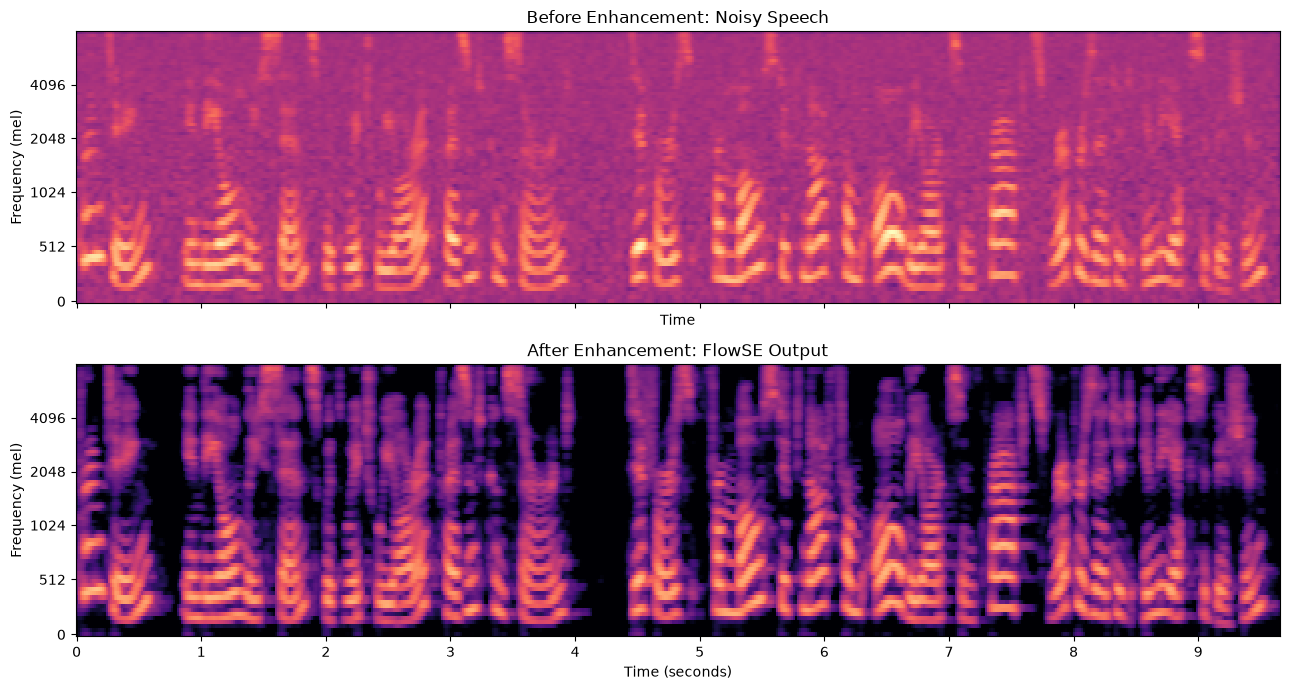

In [ ]:
comparison_sr = sr_enhanced
comparison_n_fft = 2048

mel_noisy_comparison = librosa.feature.melspectrogram(y=wav_noisy, sr=sr_noisy, n_fft=comparison_n_fft, hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=0, fmax=comparison_sr / 2, power=2.0)
mel_enhanced = librosa.feature.melspectrogram(y=enhanced, sr=sr_enhanced, n_fft=comparison_n_fft, hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=0, fmax=comparison_sr / 2, power=2.0)

comparison_reference = max(float(mel_noisy_comparison.max()), float(mel_enhanced.max()), 1e-10)

noisy_comparison_db = librosa.power_to_db(mel_noisy_comparison, ref=comparison_reference, top_db=80)

enhanced_comparison_db = librosa.power_to_db(mel_enhanced, ref=comparison_reference, top_db=80)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, spectrogram, title in [
    (axes[0], noisy_comparison_db, "Before Enhancement: Noisy Speech"),
    (axes[1],enhanced_comparison_db,"After Enhancement: FlowSE Output"),
]:
    librosa.display.specshow(spectrogram, sr=comparison_sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", vmin=-80, vmax=0, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Frequency (mel)")

axes[-1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

## Flow Matching Architecture - Details

## Flow Matching Low-Level Implementation

## Summary